# Circuit-level noise

Build an LP code memory circuit with circuit-level noise (LRCCircuitBuilder) and draw it.

In [1]:
from collections import Counter
from IPython.display import display
from sympy import symbols, Poly

from core.CSS import LPCode
from core.codes import LPCodePatch
from surgery.surgery_circuit_cl import LRCCircuitBuilder

## LP code memory circuit

In [2]:
x = symbols('x')
ring = Poly(x**3+1, x, modulus=2)
Ha = [[Poly(1+x**2,x, modulus=2),Poly(x+x**2,x, modulus=2)],
        [Poly(1+x,x, modulus=2),Poly(x+x**2,x, modulus=2)]]
Hb = [[Poly(1+x**2,x, modulus=2),Poly(x+x**2,x, modulus=2)],
        [Poly(1+x,x, modulus=2),Poly(1+x,x, modulus=2)]]
lp1 = LPCode(Ha=Ha, Hb=Hb, R=ring)  # [[24,8,3]] code

op = [[0]*24 for _ in range(8)]
for i in range(8):
    op[i][3*i:3*i+3] = [1]*3
lp1.set_logical_representatives(op, op)
patch = LPCodePatch(css=lp1, patch_name="lp_patch1")

circ = LRCCircuitBuilder(patch, 2, 0.001, 0.001)
# left = left sector qubits of the LP code
ca, rb, p = len(lp1.Ha[0]), len(lp1.Hb), lp1.l
left = list(range(ca*rb*p))
circ.set_partition(left)
# ancilla coordinates = check coordinates of the patch
circ.set_ancilla_coord([patch.local_coord_chk("Z", i) for i in range(len(patch.z_checks()))]
                       + [patch.local_coord_chk("X", i) for i in range(len(patch.x_checks()))])
stim_circ = circ.build()

# meas_record
# print(f"\n=== meas_record ({len(circ.meas_record)} entries) ===")
# for entry in circ.meas_record.values():
#     print(f"  idx={entry['meas_idx']:3d} | tick={str(entry['tick']):>4} | gate={entry['gate']:<4} | target={entry['target']:3d} | check={entry['check']} | label={entry['label']}")

print(f"\n=== total meas_count: {circ.meas_count} ===")

# measurements per tick
print("\n=== measurements per tick ===")
tick_counts = Counter(e["tick"] for e in circ.meas_record.values())
for tick in sorted(tick_counts.keys(), key=lambda x: (x is None, x)):
    entries = [e for e in circ.meas_record.values() if e["tick"] == tick]
    gates = set(e["gate"] for e in entries)
    print(f"  tick={str(tick):>4}: {tick_counts[tick]:3d} measurements, gates={gates}")

# stim circuit measurement count vs meas_count
print(f"\n=== consistency check ===")
print(f"  stim_circ.num_measurements : {stim_circ.num_measurements}")
print(f"  circ.meas_count            : {circ.meas_count}")
print(f"  match: {stim_circ.num_measurements == circ.meas_count}")


=== total meas_count: 73 ===

=== measurements per tick ===
  tick=  10:  12 measurements, gates={'M'}
  tick=  14:  12 measurements, gates={'MX'}
  tick=  17:   1 measurements, gates={'M'}
  tick=  27:  12 measurements, gates={'M'}
  tick=  31:  12 measurements, gates={'MX'}
  tick=  37:  12 measurements, gates={'M'}
  tick=  41:  12 measurements, gates={'MX'}

=== consistency check ===
  stim_circ.num_measurements : 73
  circ.meas_count            : 73
  match: True


## Timeslice diagram

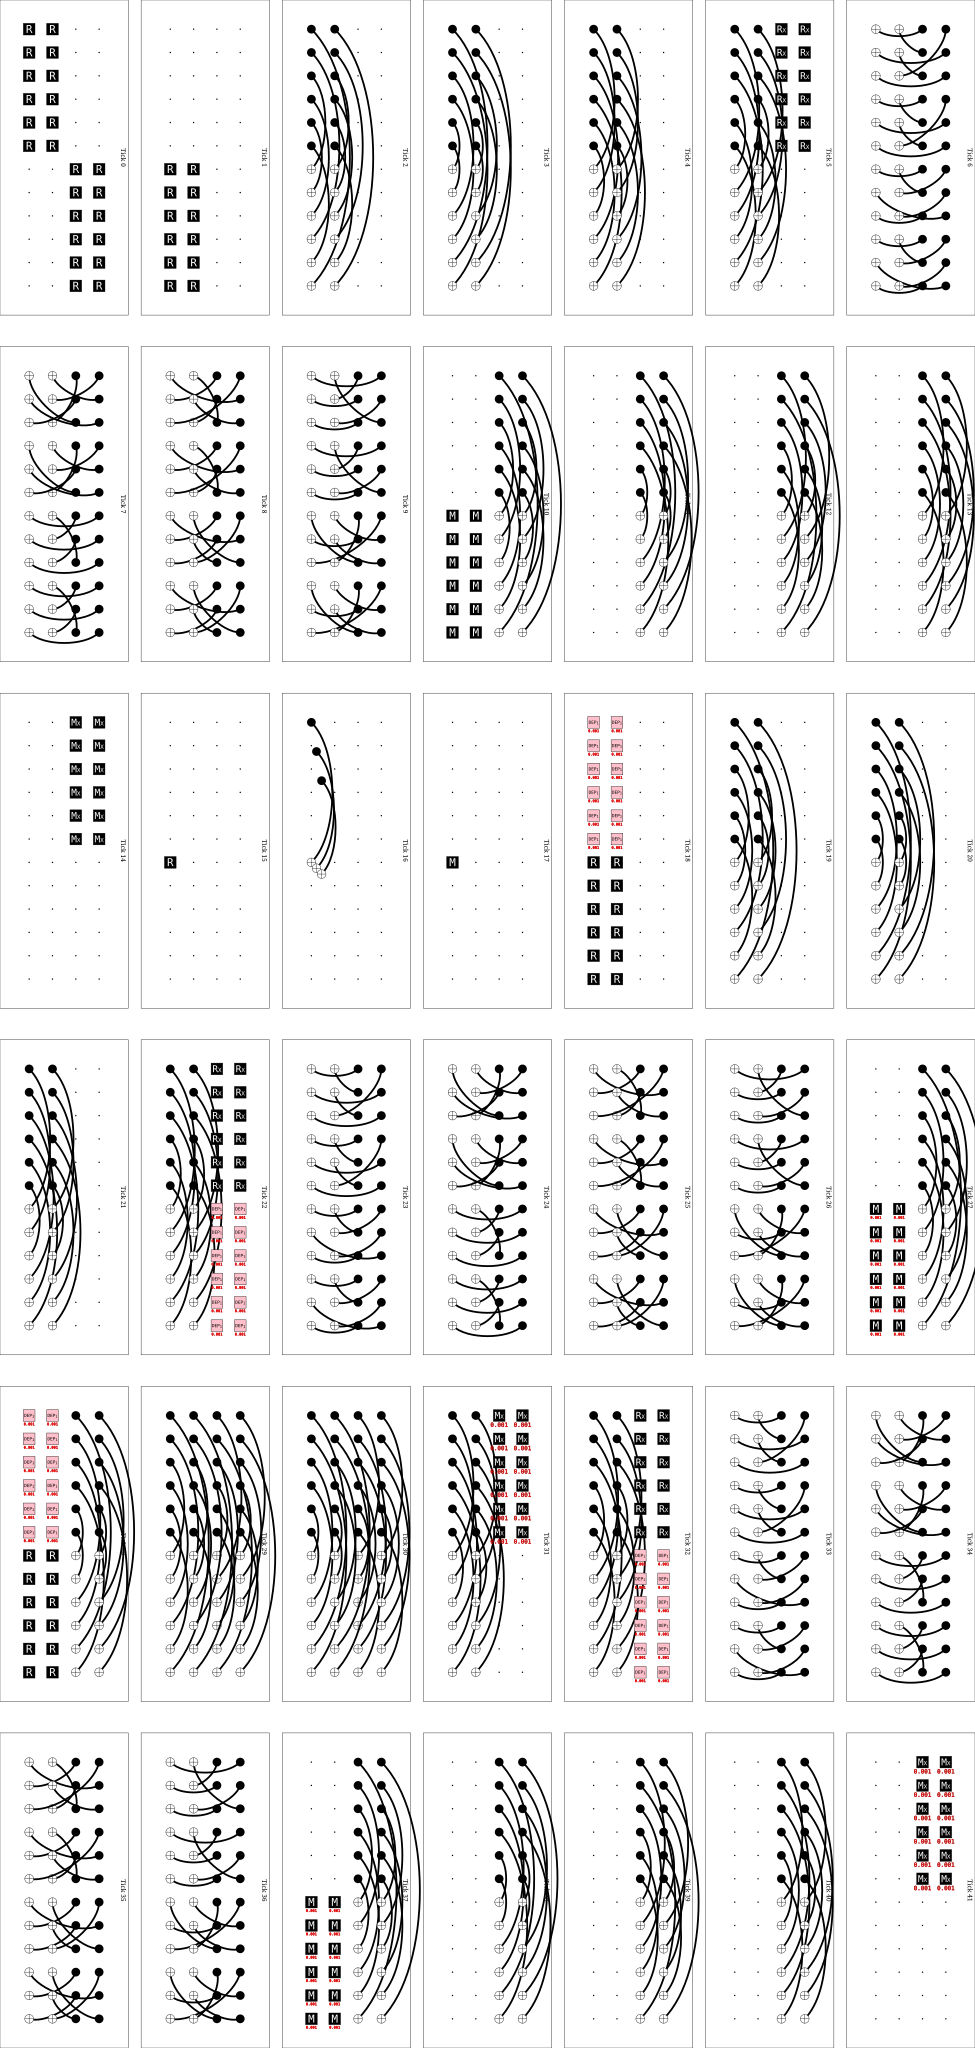

In [3]:
display(stim_circ.diagram("timeslice-svg", tick=range(0, stim_circ.num_ticks)))